In [19]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

In [54]:
DATA_DIR <- "/home/mariya/Data/pallas"
MIXOMICS_DIR <- file.path(DATA_DIR, "mixOmics/keepX_200")
PREDICTIONS_OUTPUT_DIR <- file.path(MIXOMICS_DIR, "predictions/keepX_200")

DATA_DIR <- file.path(DATA_DIR, "mlomix_datasets")

TRAIN_DATA_DIR <- file.path(DATA_DIR, "train-bimodal")
TRAIN_LABELS_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")

TEST_DATA_DIR <- file.path(DATA_DIR, "test-bimodal")
METH_TEST_FILE <- file.path(TEST_DATA_DIR, "features.dnam.csv")
GEX_TEST_FILE <- file.path(TEST_DATA_DIR, "features.gex.csv")
LABELS_TEST_FILE <- file.path(TEST_DATA_DIR, "labels.csv")

GEX_MODEL_FILE <- file.path(MIXOMICS_DIR, "gex_model.rds")
DNAM_MODEL_FILE <- file.path(MIXOMICS_DIR, "dnam_model.rds")
DIABLO_MODEL_FILE <- file.path(MIXOMICS_DIR, "diablo_model.rds")

# Make output directory if it doesn't exist
if (!dir.exists(PREDICTIONS_OUTPUT_DIR)) {
    dir.create(PREDICTIONS_OUTPUT_DIR, recursive = TRUE)
}

In [21]:
# Reload in a fresh session with
gex_model    <- readRDS(GEX_MODEL_FILE)
dnam_model   <- readRDS(DNAM_MODEL_FILE)
diablo_model <- readRDS(DIABLO_MODEL_FILE)

In [22]:
source("helpers.R")
test_data <- data(GEX_TEST_FILE, METH_TEST_FILE, LABELS_TEST_FILE)

Samples: 356 
GEX features: 19499 
DNAm features: 186411 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [58]:
# Also read in train labels to use in charts
train_labels <- read.csv(TRAIN_LABELS_FILE, row.names = 1)
train_labels

,class
,<chr>
ALL_1005,"B-ALL, MEF2D-r"
ALL_1019,"B-ALL, ZNF384-r"
ALL_1039,"B-ALL, BCR::ABL1"
ALL_1047,"B-ALL, ETV6::RUNX1-like"
ALL_1056,"B-ALL, MEF2D-r"
ALL_1060,"B-ALL, ETV6::RUNX1"
ALL_1061,"B-ALL, PAX5alt"
ALL_1081,"B-ALL, TCF3::PBX1"
ALL_1096,"B-ALL, ZNF384-r"


In [59]:
X_gex_test <- test_data$X_gex
X_dnam_test <- test_data$X_dnam
Y_test     <- test_data$Y
Y_train    <- train_labels$class

head(X_gex_test)
head(X_dnam_test)
head(Y_test)
head(Y_train)

,ENSG00000000003,ENSG00000000005,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,⋯,ENSG00000288825,ENSG00000288859,ENSG00000288867,ENSG00000289549,ENSG00000289604,ENSG00000290292,ENSG00000291237,ENSG00000293137,ENSG00000293560,ENSG00000310560
ALL_1023,-1.650607,-2.0435611,3.789595,1.901064,2.416145,4.774501,3.3746071,2.978500,3.218238,4.258658,⋯,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-1.4612092,-2.043561,7.383472
ALL_1026,-1.202757,-2.0435611,6.621405,6.825936,5.592961,10.585112,2.9859724,3.800386,6.553812,5.002018,⋯,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-0.5384626,-2.043561,3.934381
ALL_106,-1.490602,-2.0435611,4.160126,5.802877,4.451814,9.490535,1.8448724,3.079237,6.012239,5.345225,⋯,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,1.1491763,-2.043561,5.117272
ALL_1062,-1.925542,-2.0435611,4.943673,6.700398,6.239570,4.058467,0.6110613,5.950289,3.642400,3.628827,⋯,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,0.8967897,-1.823604,4.720199
ALL_1065,-1.472229,-2.0435611,3.023832,2.685842,1.661090,8.001246,6.9705759,6.149729,5.097503,3.724097,⋯,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-1.3238716,-2.043561,5.300463
ALL_1072,-1.505871,0.2043482,4.086500,5.448004,4.622936,5.975758,5.0639538,3.717171,3.287946,5.529434,⋯,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-2.043561,-0.4958080,2.375271,1.364021


,cg00000029,cg00000109,cg00000165,cg00000236,cg00000289,cg00000292,cg00000321,cg00000363,cg00000714,cg00000721,⋯,ch.4.194519R,ch.4.2662600F,ch.4.3427878R,ch.6.115952F,ch.6.1693624F,ch.6.92327598R,ch.7.130270068F,ch.7.1839793F,ch.9.2043201R,ch.9.31239617R
ALL_1023,0.9021,0.8852,0.1705,0.9225,0.7927,0.9332,0.7015,0.2693,0.1749,0.9492,⋯,0.0138,0.0721,0.0729,0.0389,0.0866,0.1162,0.0269,0.0480,0.0305,0.0660
ALL_1026,0.7359,0.9112,0.3087,0.9234,0.7405,0.4220,0.8142,0.2090,0.1019,0.9523,⋯,0.0201,0.0600,0.0897,0.0363,0.0629,0.1113,0.0309,0.0484,0.0353,0.0505
ALL_106,0.7661,0.9426,0.0968,0.9440,0.9063,0.5613,0.5793,0.2937,0.5087,0.9709,⋯,0.0225,0.0656,0.0505,0.0306,0.0550,0.0805,0.0317,0.0466,0.0298,0.0434
ALL_1062,0.7528,0.6751,0.8232,0.8989,0.6597,0.9336,0.5882,0.6953,0.1606,0.9322,⋯,0.0117,0.0847,0.0681,0.0348,0.0514,0.0732,0.0273,0.1096,0.0333,0.0499
ALL_1065,0.8559,0.8855,0.1035,0.8991,0.6955,0.8501,0.4196,0.2667,0.2327,0.9317,⋯,0.0184,0.1015,0.0554,0.0421,0.1277,0.0611,0.0220,0.0681,0.0381,0.0497
ALL_1072,0.4531,0.8945,0.1074,0.9023,0.7524,0.9380,0.6396,0.5650,0.2310,0.9360,⋯,0.0118,0.0596,0.0481,0.0312,0.0707,0.0759,0.0234,0.0493,0.0281,0.0556


[1] B-ALL, ETV6::RUNX1      B-ALL, PAX5alt          B-ALL, ETV6::RUNX1-like
[4] B-ALL, MEF2D-r          B-ALL, TCF3::PBX1       B-ALL, BCR::ABL1-like  
25 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

[1] "B-ALL, MEF2D-r"          "B-ALL, ZNF384-r"        
[3] "B-ALL, BCR::ABL1"        "B-ALL, ETV6::RUNX1-like"
[5] "B-ALL, MEF2D-r"          "B-ALL, ETV6::RUNX1"

In [24]:
# X_gex_test  <- X_gex_test[,  colnames(gex_model$X)]
# X_dnam_test <- X_dnam_test[, colnames(dnam_model$X)]

# Verify
cat("GEX names match: ",  all(colnames(X_gex_test)  == colnames(gex_model$X)),  "\n")
cat("DNAm names match:",  all(colnames(X_dnam_test) == colnames(dnam_model$X)), "\n")

# Show number of features in test set vs model
cat("GEX features in test set: ", ncol(X_gex_test), " vs model: ", ncol(gex_model$X), "\n")
cat("DNAm features in test set: ", ncol(X_dnam_test), " vs model: ", ncol(dnam_model$X), "\n")

GEX names match:  TRUE 
DNAm names match: TRUE 
GEX features in test set:  19499  vs model:  19499 
DNAm features in test set:  186411  vs model:  186411 


In [25]:

gex_pred    <- predict(gex_model,    X_gex_test,  dist = "max.dist")
dnam_pred   <- predict(dnam_model,   X_dnam_test, dist = "max.dist")
diablo_pred <- predict(diablo_model, newdata = list(gex = X_gex_test,
                                                     dnam = X_dnam_test),
                                                     dist = "max.dist")

In [26]:
# Extract predicted classes at final component
ncomp_gex_final    <- gex_model$ncomp
ncomp_dnam_final   <- dnam_model$ncomp
ncomp_diablo_final <- diablo_model$ncomp

gex_class    <- gex_pred$class$max.dist[,    ncomp_gex_final]
dnam_class   <- dnam_pred$class$max.dist[,   ncomp_dnam_final]
diablo_class <- diablo_pred$WeightedVote$max.dist[, ncol(diablo_pred$WeightedVote$max.dist)]

In [27]:
# Make predictiosn dir if not exist
if (!dir.exists(PREDICTIONS_OUTPUT_DIR)) {
    dir.create(PREDICTIONS_OUTPUT_DIR, recursive = TRUE)
}

# After true_label, create three cols: gex_pred, dnam_pred, diablo_pred
# that contain the prediction from the MAX_COMP component for each model
# Keep the rest of the columns as well
predictions_df <- data.frame(
    "Sample" = rownames(X_gex_test),
    "True subtype" = Y_test,
    "GEX sPLS-DA prediction" = gex_class,
    "DNAm sPLS-DA prediction" = dnam_class,
    "DIABLO sPLS-DA prediction" = diablo_class,
    "GEX" = gex_pred$class,
    "DNAm" = dnam_pred$class,
    "DIABLO" = diablo_pred$class,
    check.names = FALSE
)

# Sort by "True subtype", then "Sample"
predictions_df <- predictions_df[order(predictions_df$`True subtype`, predictions_df$Sample), ]

write.csv(predictions_df, file.path(PREDICTIONS_OUTPUT_DIR, "test_predictions.csv"), row.names = FALSE)

In [28]:
# Build results data frame
results_df <- data.frame(
  sample_id   = rownames(X_gex_test),
  true_label  = as.character(Y_test),
  gex_pred    = as.character(gex_class),
  dnam_pred   = as.character(dnam_class),
  diablo_pred = as.character(diablo_class),
  row.names   = NULL
)

head(results_df)

,sample_id,true_label,gex_pred,dnam_pred,diablo_pred
,<chr>,<chr>,<chr>,<chr>,<chr>
1,ALL_1023,"B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1"
2,ALL_1026,"B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt"
3,ALL_106,"B-ALL, ETV6::RUNX1-like","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1-like","B-ALL, ETV6::RUNX1"
4,ALL_1062,"B-ALL, MEF2D-r","B-ALL, MEF2D-r","B-ALL, MEF2D-r","B-ALL, MEF2D-r"
5,ALL_1065,"B-ALL, TCF3::PBX1","B-ALL, TCF3::PBX1","B-ALL, TCF3::PBX1","B-ALL, TCF3::PBX1"
6,ALL_1072,"B-ALL, BCR::ABL1-like",Non-leukemic,"B-ALL, BCR::ABL1-like","B-ALL, PAX5alt"


In [74]:

library(ggplot2)
library(dplyr)
library(tidyr)
library(ggrepel)

# Per-class F1
per_class_f1 <- function(true, pred, classes) {
  do.call(rbind, lapply(classes, function(c) {
    tp <- sum(pred == c & true == c)
    fp <- sum(pred == c & true != c)
    fn <- sum(pred != c & true == c)
    precision <- ifelse((tp + fp) == 0, 0, tp / (tp + fp))
    recall    <- ifelse((tp + fn) == 0, 0, tp / (tp + fn))
    f1        <- ifelse((precision + recall) == 0, 0,
                        2 * precision * recall / (precision + recall))
    data.frame(Class = c, Precision = round(precision, 3),
               Recall = round(recall, 3), F1 = round(f1, 3))
  }))
}

classes <- levels(Y_test)

f1_gex    <- per_class_f1(Y_test, gex_class,    classes); f1_gex$Model    <- "GEX"
f1_dnam   <- per_class_f1(Y_test, dnam_class,   classes); f1_dnam$Model   <- "DNAm"
f1_diablo <- per_class_f1(Y_test, diablo_class, classes); f1_diablo$Model <- "DIABLO"

f1_all  <- rbind(f1_gex, f1_dnam, f1_diablo)
f1_wide <- f1_all |> select(Class, Model, F1) |>
  pivot_wider(names_from = Model, values_from = F1)

# Add class sizes
class_n_train       <- as.data.frame(table(Y_train))
colnames(class_n_train) <- c("Class", "n_train")
f1_wide        <- left_join(f1_wide, class_n_train, by = "Class")

class_n_test        <- as.data.frame(table(Y_test))
colnames(class_n_test) <- c("Class", "n_test")
f1_wide        <- left_join(f1_wide, class_n_test, by = "Class")
f1_wide

Class,GEX,DNAm,DIABLO,n_train,n_test
<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>
"AML, APL-PML::RARA",1.000,1.000,1.000,10,4
"AML, CBFA2T3::GLIS2",0.750,0.667,0.667,9,4
"AML, CBFB::MYH11",0.980,1.000,0.980,57,25
"AML, CEBPAalt",0.909,0.950,0.927,50,21
"AML, DEK::NUP214",1.000,1.000,1.000,19,8
"AML, ETV6-r",0.800,1.000,0.800,6,3
"AML, KAT6A-r",1.000,0.667,0.000,5,2
"AML, KMT2A-r",0.936,0.921,0.905,211,91
"AML, NPM1alt",0.821,0.932,0.889,116,50


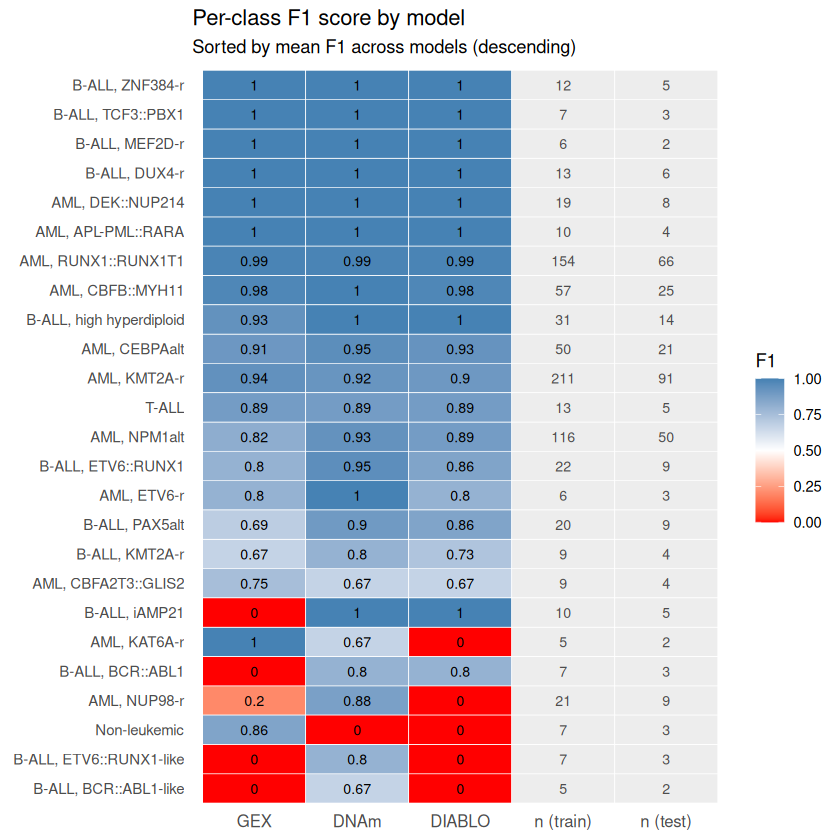

In [80]:
# Add average F1 column for sorting
f1_wide <- f1_wide %>%
  mutate(avg_F1 = (GEX + DNAm + DIABLO) / 3)

# Pivot to long including n_train and n_test as separate tile columns
f1_long <- f1_wide %>%
  pivot_longer(cols = c("GEX", "DNAm", "DIABLO"),
               names_to = "Model", values_to = "F1")

# Create n_train and n_test rows as separate "columns"
n_df <- f1_wide %>%
  select(Class, n_train, n_test, avg_F1) %>%
  pivot_longer(cols = c("n_train", "n_test"),
               names_to = "Model", values_to = "n_val") %>%
  mutate(F1 = NA)

# Combine
f1_plot_df <- bind_rows(
  f1_long %>% mutate(n_val = NA),
  n_df
) %>%
  mutate(Model = factor(Model,
                        levels = c("GEX", "DNAm", "DIABLO",
                                   "n_train", "n_test")))

ggplot(f1_plot_df,
       aes(x = Model,
           y = reorder(Class, avg_F1),
           fill = F1)) +
  geom_tile(colour = "white") +
  # F1 values
  geom_text(data = filter(f1_plot_df, Model %in% c("GEX","DNAm","DIABLO")),
            aes(label = round(F1, 2)), size = 3) +
  # n_train and n_test values
  geom_text(data = filter(f1_plot_df, Model %in% c("n_train","n_test")),
            aes(label = n_val), size = 3, colour = "grey30") +
  scale_fill_gradient2(low       = "red",
                       mid       = "white",
                       high      = "steelblue",
                       midpoint  = 0.5,
                       limits    = c(0, 1),
                       na.value  = "grey93",
                       name      = "F1") +
  scale_x_discrete(labels = c("GEX", "DNAm", "DIABLO",
                               "n (train)", "n (test)")) +
  labs(title = "Per-class F1 score by model",
       subtitle = "Sorted by mean F1 across models (descending)",
       x = NULL, y = NULL) +
  theme_minimal() +
  theme(axis.text.x  = element_text(size = 10),
        axis.text.y  = element_text(size = 9),
        legend.position = "right",
        panel.grid   = element_blank())

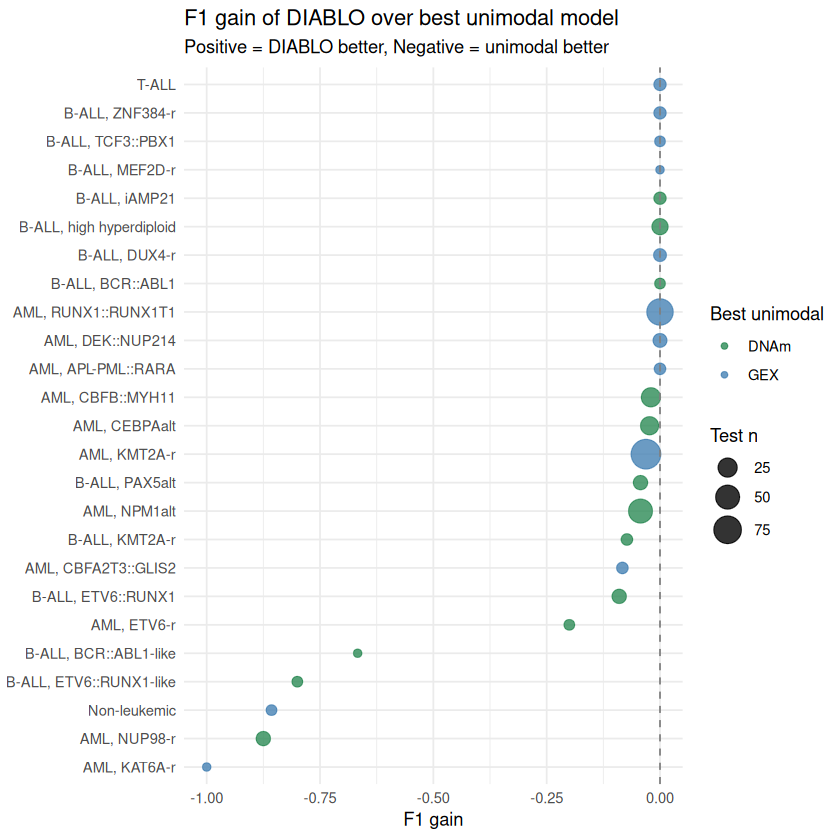

In [31]:
f1_wide <- f1_wide |>
  mutate(
    Best_unimodal    = pmax(GEX, DNAm),
    DIABLO_gain      = DIABLO - Best_unimodal,
    Best_unimodal_name = ifelse(GEX >= DNAm, "GEX", "DNAm")
  )

ggplot(f1_wide, aes(x = DIABLO_gain,
                     y = reorder(Class, DIABLO_gain),
                     colour = Best_unimodal_name,
                     size = n)) +
  geom_point(alpha = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey50") +
  scale_colour_manual(values = c(GEX = "steelblue", DNAm = "seagreen"),
                      name = "Best unimodal") +
  scale_size_continuous(range = c(2, 8), name = "Test n") +
  labs(title    = "F1 gain of DIABLO over best unimodal model",
       subtitle = "Positive = DIABLO better, Negative = unimodal better",
       x = "F1 gain", y = NULL) +
  theme_minimal()

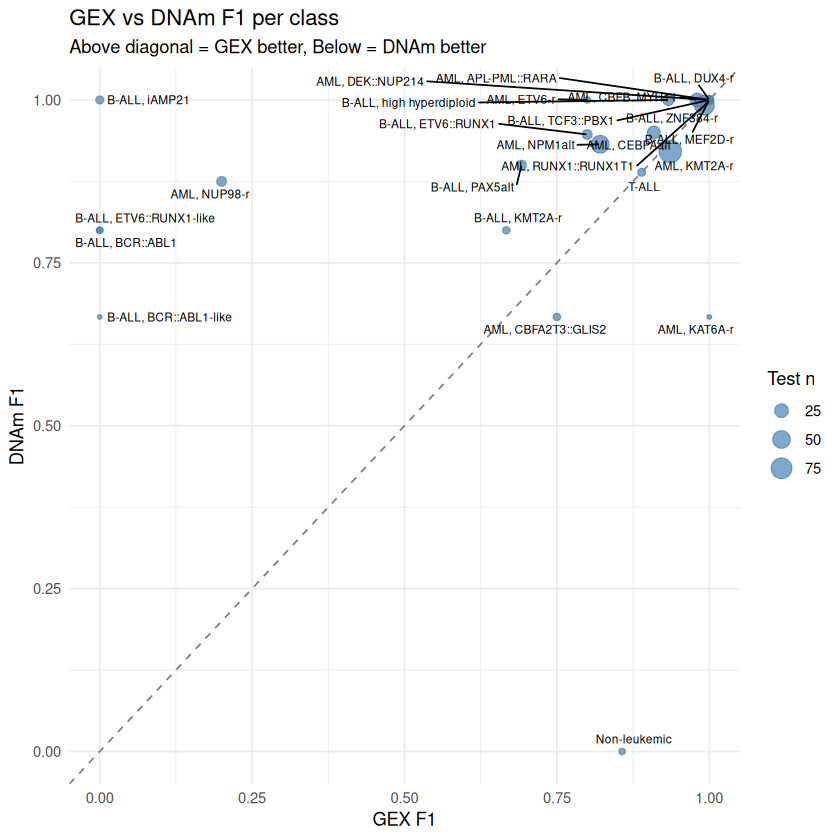

In [32]:
ggplot(f1_wide, aes(x = GEX, y = DNAm, size = n, label = Class)) +
  geom_point(alpha = 0.7, colour = "steelblue") +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  geom_text_repel(size = 2.5, max.overlaps = 20) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title    = "GEX vs DNAm F1 per class",
       subtitle = "Above diagonal = GEX better, Below = DNAm better",
       x = "GEX F1", y = "DNAm F1", size = "Test n") +
  theme_minimal()

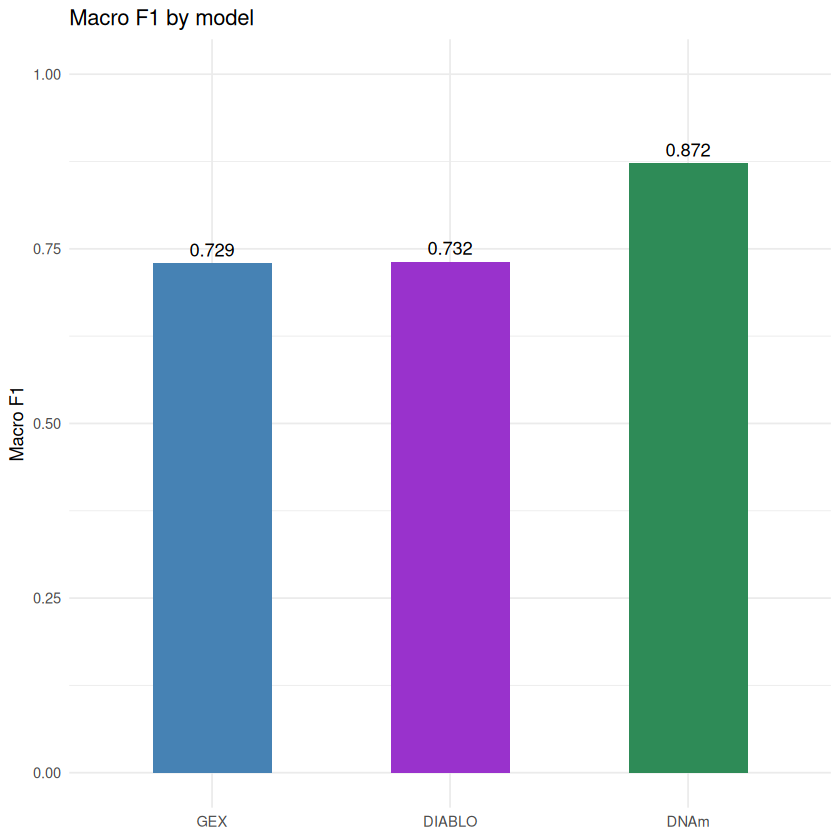

In [33]:
macro_f1 <- f1_all |>
  group_by(Model) |>
  summarise(MacroF1 = mean(F1), .groups = "drop")

ggplot(macro_f1, aes(x = reorder(Model, MacroF1), y = MacroF1, fill = Model)) +
  geom_bar(stat = "identity", width = 0.5) +
  geom_text(aes(label = round(MacroF1, 3)), vjust = -0.5) +
  scale_fill_manual(values = c(GEX = "steelblue",
                                DNAm = "seagreen",
                                DIABLO = "darkorchid")) +
  ylim(0, 1) +
  labs(title = "Macro F1 by model", x = NULL, y = "Macro F1") +
  theme_minimal() +
  theme(legend.position = "none")

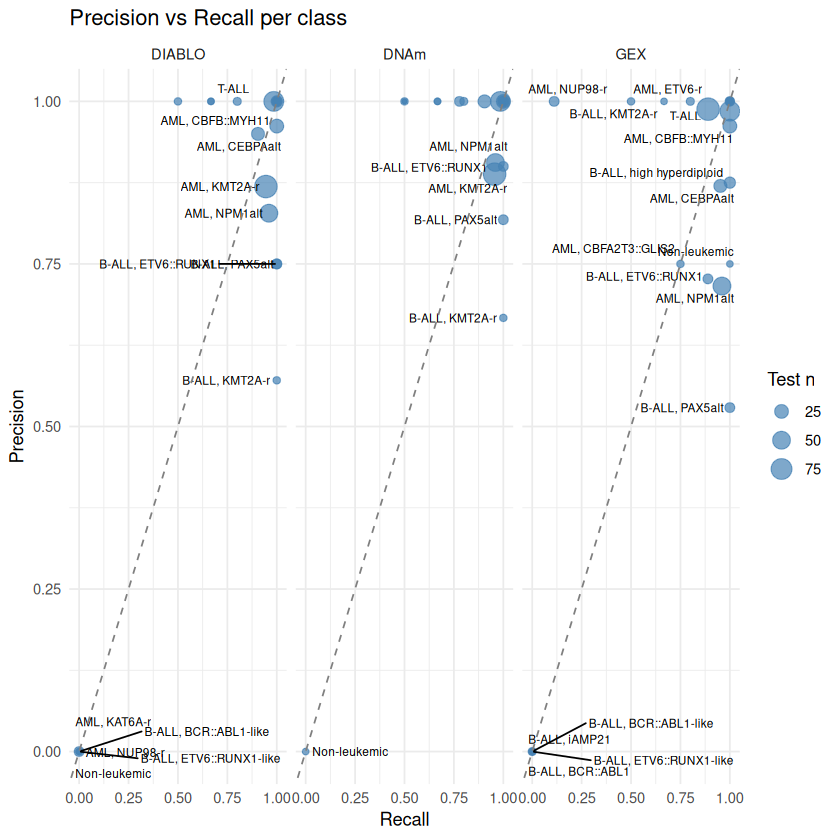

In [34]:
f1_all |>
  left_join(class_n, by = "Class") |>
ggplot(aes(x = Recall, y = Precision, size = n, label = Class)) +
  geom_point(alpha = 0.7, colour = "steelblue") +
  geom_text_repel(size = 2.5, max.overlaps = 15) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  facet_wrap(~ Model) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title = "Precision vs Recall per class",
       size = "Test n") +
  theme_minimal()

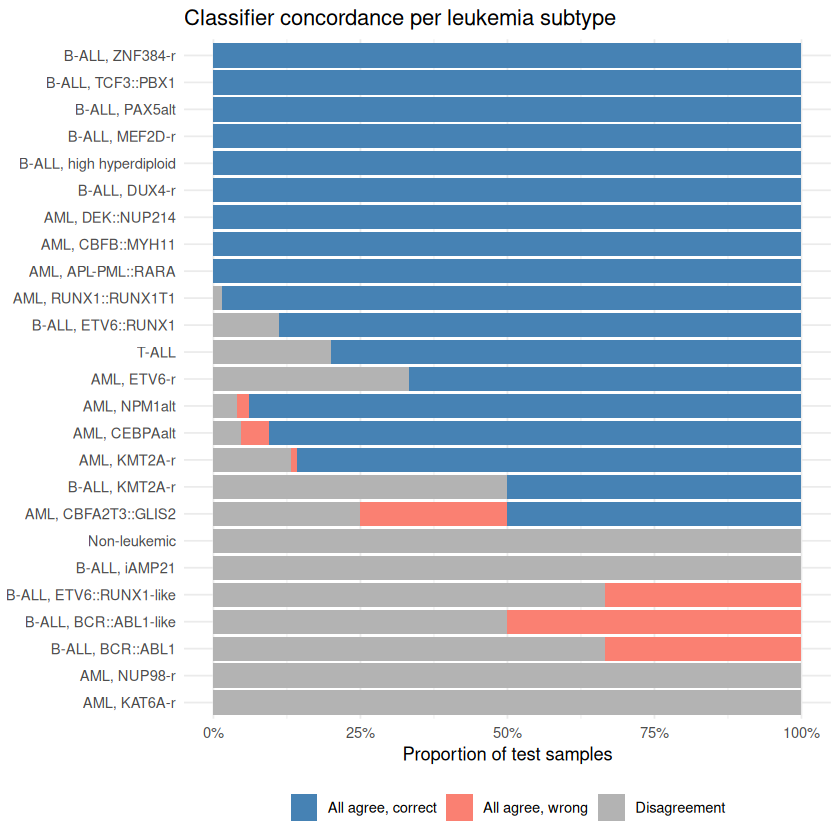

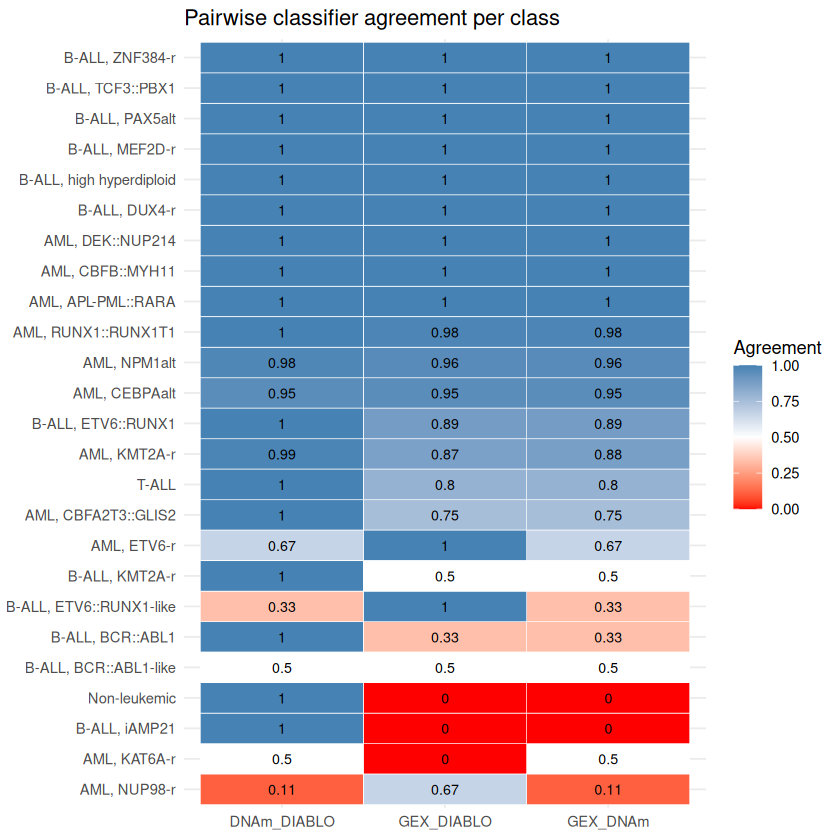

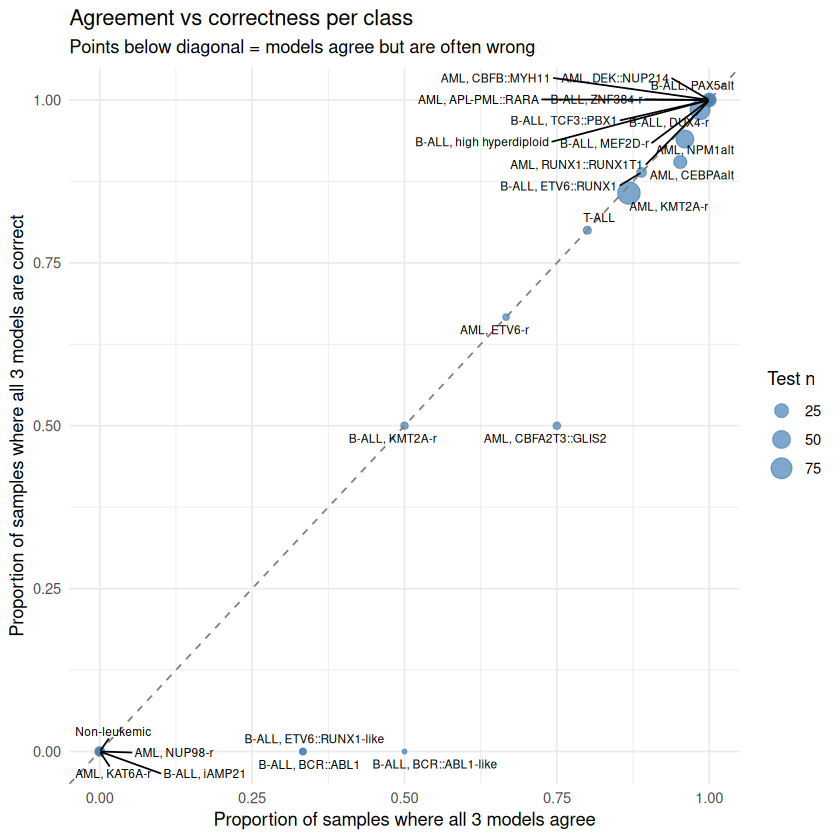

In [35]:
library(ggplot2)
library(dplyr)

# ============================================================
# Compute per-sample concordance
# ============================================================
results_df <- results_df |>
  mutate(
    # How many models agree with each other
    n_agree = (gex_pred == dnam_pred) +
              (gex_pred == diablo_pred) +
              (dnam_pred == diablo_pred),

    # All three agree
    all_agree = gex_pred == dnam_pred & dnam_pred == diablo_pred,

    # All three agree AND correct
    all_correct = all_agree & gex_pred == true_label,

    # Concordance label
    concordance = case_when(
      all_agree & gex_pred == true_label  ~ "All agree, correct",
      all_agree & gex_pred != true_label  ~ "All agree, wrong",
      !all_agree                           ~ "Disagreement"
    )
  )

# ============================================================
# 1. Stacked bar — concordance per true class
# ============================================================
conc_summary <- results_df |>
  group_by(true_label, concordance) |>
  summarise(n = n(), .groups = "drop") |>
  group_by(true_label) |>
  mutate(pct = n / sum(n))

ggplot(conc_summary,
       aes(x = pct,
           y = reorder(true_label, pct * (concordance == "All agree, correct")),
           fill = concordance)) +
  geom_bar(stat = "identity") +
  scale_fill_manual(values = c("All agree, correct" = "steelblue",
                                "All agree, wrong"   = "salmon",
                                "Disagreement"       = "grey70")) +
  scale_x_continuous(labels = scales::percent) +
  labs(title = "Classifier concordance per leukemia subtype",
       x = "Proportion of test samples", y = NULL, fill = NULL) +
  theme_minimal() +
  theme(legend.position = "bottom")

# ============================================================
# 2. Tile plot — pairwise agreement per class
# ============================================================
pairwise <- results_df |>
  group_by(true_label) |>
  summarise(
    GEX_DNAm    = mean(gex_pred == dnam_pred),
    GEX_DIABLO  = mean(gex_pred == diablo_pred),
    DNAm_DIABLO = mean(dnam_pred == diablo_pred),
    .groups = "drop"
  ) |>
  pivot_longer(cols = c("GEX_DNAm","GEX_DIABLO","DNAm_DIABLO"),
               names_to = "Pair", values_to = "Agreement")

ggplot(pairwise, aes(x = Pair,
                      y = reorder(true_label, Agreement),
                      fill = Agreement)) +
  geom_tile(colour = "white") +
  scale_fill_gradient2(low = "red", mid = "white", high = "steelblue",
                       midpoint = 0.5, limits = c(0, 1)) +
  geom_text(aes(label = round(Agreement, 2)), size = 3) +
  labs(title = "Pairwise classifier agreement per class",
       x = NULL, y = NULL, fill = "Agreement") +
  theme_minimal()

# ============================================================
# 3. Scatter — per class: % all-agree vs % correct
# ============================================================
class_conc <- results_df |>
  group_by(true_label) |>
  summarise(
    n          = n(),
    pct_agree  = mean(all_agree),
    pct_correct = mean(gex_pred == true_label &
                       dnam_pred == true_label &
                       diablo_pred == true_label),
    .groups = "drop"
  )

ggplot(class_conc, aes(x = pct_agree, y = pct_correct,
                        size = n, label = true_label)) +
  geom_point(alpha = 0.7, colour = "steelblue") +
  geom_abline(slope = 1, intercept = 0,
              linetype = "dashed", colour = "grey50") +
  geom_text_repel(size = 2.5, max.overlaps = 20) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title    = "Agreement vs correctness per class",
       subtitle = "Points below diagonal = models agree but are often wrong",
       x = "Proportion of samples where all 3 models agree",
       y = "Proportion of samples where all 3 models are correct",
       size = "Test n") +
  theme_minimal()

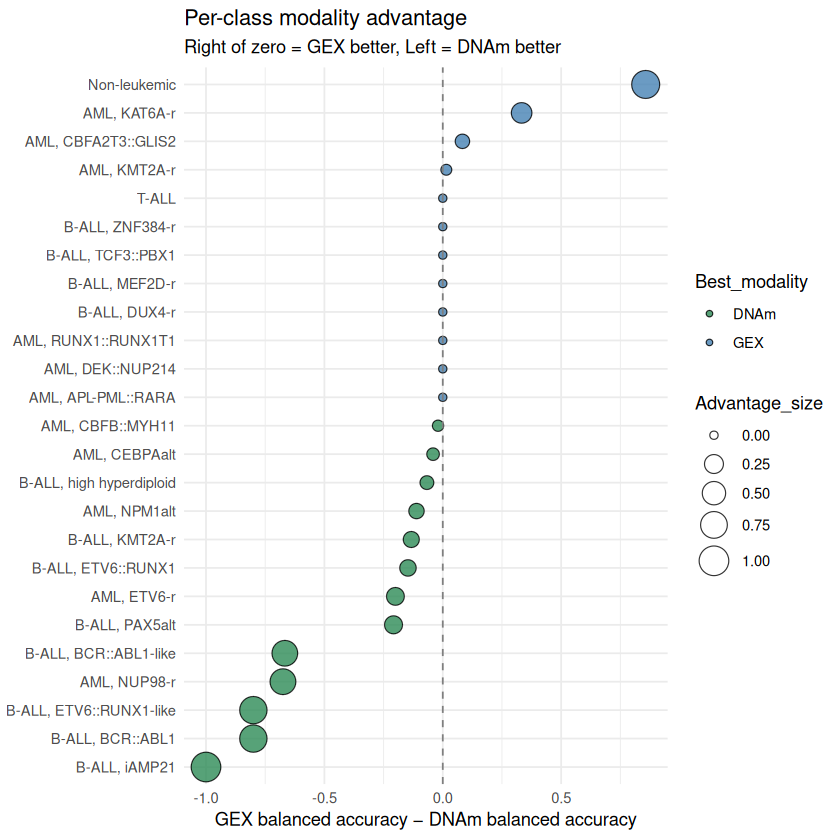

In [36]:
# Using per_class_f1() from earlier
complement_df <- data.frame(
  Class = classes,
  GEX   = f1_gex$F1,
  DNAm  = f1_dnam$F1
) |>
  mutate(
    GEX_advantage  = GEX - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  )

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = Advantage_size)) +
  geom_point(shape = 21, alpha = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey50") +
  scale_fill_manual(values = c(GEX = "steelblue", DNAm = "seagreen")) +
  scale_size_continuous(range = c(2, 8)) +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x = "GEX balanced accuracy − DNAm balanced accuracy",
       y = NULL) +
  theme_minimal()


In [49]:

# Extract F1 vectors per model
f1_gex_vec    <- f1_wide$GEX
f1_dnam_vec   <- f1_wide$DNAm
f1_diablo_vec <- f1_wide$DIABLO

# ============================================================
# Pairwise Wilcoxon signed-rank tests
# ============================================================
wt_gex_dnam   <- wilcox.test(f1_gex_vec, f1_dnam_vec,
                              paired = TRUE, exact = FALSE)
wt_gex_diablo <- wilcox.test(f1_gex_vec, f1_diablo_vec,
                              paired = TRUE, exact = FALSE)
wt_dnam_diablo <- wilcox.test(f1_dnam_vec, f1_diablo_vec,
                               paired = TRUE, exact = FALSE)

# ============================================================
# Summary table
# ============================================================
wilcox_results <- data.frame(
  Comparison     = c("GEX vs DNAm", "GEX vs DIABLO", "DNAm vs DIABLO"),
  Mean_F1_A      = round(c(mean(f1_gex_vec),
                            mean(f1_gex_vec),
                            mean(f1_dnam_vec)), 3),
  Mean_F1_B      = round(c(mean(f1_dnam_vec),
                            mean(f1_diablo_vec),
                            mean(f1_diablo_vec)), 3),
  W_statistic    = c(wt_gex_dnam$statistic,
                     wt_gex_diablo$statistic,
                     wt_dnam_diablo$statistic),
  p_value        = round(c(wt_gex_dnam$p.value,
                            wt_gex_diablo$p.value,
                            wt_dnam_diablo$p.value), 4),
  p_adj_BH       = round(p.adjust(c(wt_gex_dnam$p.value,
                                     wt_gex_diablo$p.value,
                                     wt_dnam_diablo$p.value),
                                   method = "BH"), 4)
)

print(wilcox_results)

      Comparison Mean_F1_A Mean_F1_B W_statistic p_value p_adj_BH
1    GEX vs DNAm     0.729     0.872        33.0  0.0418   0.0627
2  GEX vs DIABLO     0.729     0.732        41.5  0.8067   0.8067
3 DNAm vs DIABLO     0.872     0.732        78.0  0.0025   0.0075
